# Práctica 19

Mediante una regresión de mínimos cuadrados ajuste los datos del archivo anterior al modelo logístico siguiente:

$$
\hat{Y}  = \frac{1}{1 + e^{\beta_1(X - \beta_2)}}
$$

donde $X$ representa el período (año) y $\hat{Y}$ el PIB. De lo anterior es evidente que debe estimar dos parámetros ($\beta1$ y $\beta_2$ ). ¿Tuvo algún problema en el proceso de estimación de parámetros? ¿A qué crees que se debe?

#### Carga de librerias y Lectura de datos

In [1]:
#import libraries
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit  # Library for the adjust
from sklearn.metrics import r2_score  #Library to estimate the error

In [2]:
df = pd.read_excel('MexicoGDP.xlsx')
df.head(3)

,Periodo,GDP
0,1960,1.304000e+10
1,1961,1.416000e+10
2,1962,1.520000e+10


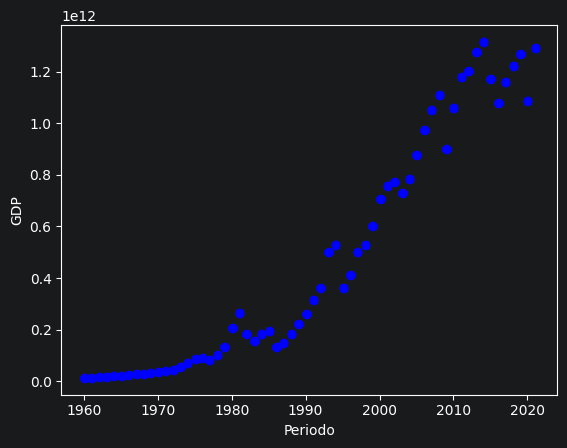

In [3]:
plt.scatter(df.Periodo, df.GDP, color = 'blue')
plt.xlabel('Periodo')
plt.ylabel('GDP')
plt.show()


#### Definición del modelo matemático

In [4]:
def logistic_equation(x, beta_1, beta_2):
    y = 1.0 / (1.0 + np.exp(-beta_1 * (x - beta_2)))
    return y

#### Asignación y normalización de los datos de entrenamiento

Normalización de los datos

In [5]:
df['GDP_normalized'] = df['GDP'] / np.max(df['GDP'])
df['Periodo_normalized'] = df['Periodo'] / np.max(df['Periodo'])


Ceeación de la mascara de datos, usando aproximadamente el 80% de los datos para  el entrenamiento


In [6]:
msk = np.random.rand(len(df)) < 0.8
msk

array([ True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False,  True,  True, False,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False,  True, False,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True])

In [12]:
train_data = df[msk]
train_data
train_x = np.asanyarray(train_data['Periodo_normalized'])
train_y = np.asanyarray(train_data['GDP_normalized'])

In [13]:
test_data = df[~msk]
test_data
test_x = np.asanyarray(test_data['Periodo_normalized'])
test_y = np.asanyarray(test_data['GDP_normalized'])

#### Aplicación y calculo de los coeficientes $\beta$

In [19]:
popt, pcov = curve_fit(logistic_equation, train_x, train_y)

In [22]:
print(f'beta_1 =  {popt[0]}, beta_2 =  {popt[1]}')

beta_1 =  283.1752432816382, beta_2 =  0.9892147362826654


La ecuación queda de la siguiente manera:
$$
\hat{Y}  = \frac{1}{1 + e^{283.17 (X - 0.98)}}
$$


In [24]:
#solution
y_hat = logistic_equation(train_x, *popt)

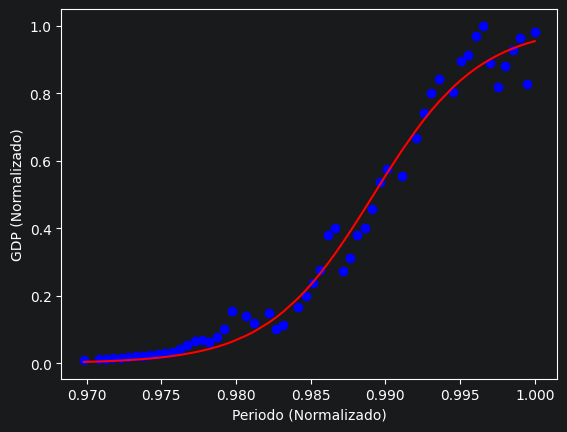

<Figure size 640x480 with 0 Axes>

In [37]:
plt.scatter(train_x, train_y, color = 'blue')
plt.plot(train_x, y_hat, color = 'red')
plt.xlabel('Periodo (Normalizado)')
plt.ylabel('GDP (Normalizado)')
plt.show()

plt.savefig('norm_fit.png')

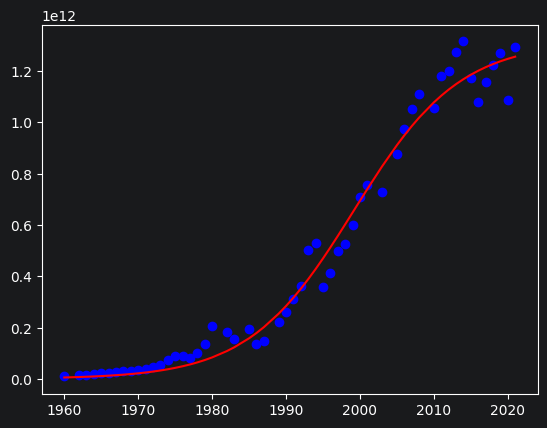

In [32]:
# non-normalized
y_hat_non_normalized = np.max(train_data['GDP']) * logistic_equation(train_x, *popt)
plt.plot(train_data['Periodo'] , y_hat_non_normalized, color = 'red')
plt.scatter(train_data['Periodo'] , train_data['GDP'], color = 'blue')


#### Cálculo de los errores

In [33]:
print(f"Mean absolute error: {np.mean(np.absolute(y_hat_non_normalized - train_data['GDP']))}")
print(f"Residual sum of squares (MSE): {np.mean((y_hat_non_normalized - train_data['GDP'])**2): .2f}")
print(f"R2-score: {r2_score(y_hat_non_normalized, train_data['GDP']): .2f}")

Mean absolute error: 48488355562.87569
Residual sum of squares (MSE):  3987635847873667530752.00
R2-score:  0.98


#### Pronostico del PIB para el 2022

In [36]:
y_hat_estimated = np.max(train_data['GDP']) * logistic_equation(2022, *popt)
print(f'y_hat_estimated = {y_hat_estimated}')

y_hat_estimated = 1315351183524.544
